# Production model example

Run after 05 exports the test-evaluated model.

In [1]:
import json
import pandas as pd
from pathlib import Path
import numpy as np
import xgboost as xgb
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Draw import SimilarityMaps
import shap
import matplotlib.pyplot as plt


RDLogger.DisableLog('rdApp.*')

c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
PROJECT_DIR = Path.cwd() if (Path.cwd() / 'Data').is_dir() else Path.cwd().parent
MODEL_DIR = PROJECT_DIR / 'Output' / 'Intermediate' / 'Final_Model'
config = json.loads((MODEL_DIR / 'Configuration.json').read_text())
model = xgb.XGBClassifier()
model.load_model(MODEL_DIR / 'Model.json')

In [3]:
# Sorafenib
smiles = 'CNC(=O)C1=NC=CC(=C1)OC2=CC=C(C=C2)NC(=O)NC3=CC(=C(C=C3)Cl)C(F)(F)F'
mol = Chem.MolFromSmiles(smiles)
mol = rdMolStandardize.ChargeParent(mol)
mol = rdMolStandardize.Uncharger().uncharge(mol)
standardized_smiles = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
mol = Chem.MolFromSmiles(standardized_smiles)

fp_config = config['fingerprint']
fp = AllChem.GetMorganFingerprintAsBitVect(
    mol, fp_config['Radius'], nBits=fp_config['nBits'],
    useFeatures=fp_config['FP_Type'] == 'FCFP', useChirality=fp_config['useChirality'])
features = np.zeros(fp_config['nBits'], dtype=np.int8)
DataStructs.ConvertToNumpyArray(fp, features)
probability = model.predict_proba(features.reshape(1, -1))[0, 1]
label = 'Promiscuous' if probability >= config['prediction_threshold'] else 'Selective'
print(f'Compound {standardized_smiles} is predicted as {label} \nP(promiscuous) = {probability:.3f} | ' f"Decision threshold = {config['prediction_threshold']:.3f}")

Compound CNC(=O)c1cc(Oc2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)c3)cc2)ccn1 is predicted as Promiscuous 
P(promiscuous) = 0.545 | Decision threshold = 0.375


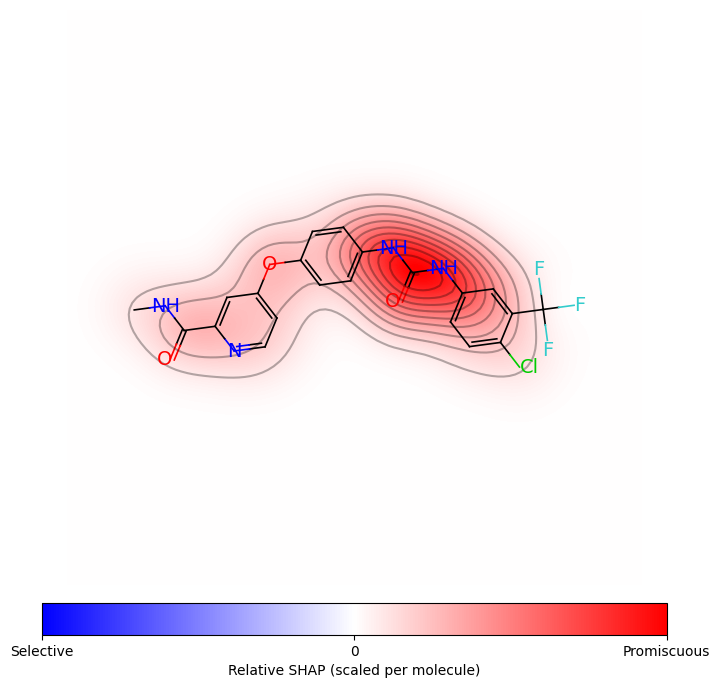

In [4]:
# Restore the training rows in their exported order for the same SHAP background.
cohort = pd.read_csv(PROJECT_DIR / 'Output' / 'Intermediate' / 'KIPS_Curated' / 'KIPS_Curated_SI65.csv').set_index('InChI_Key')
splits = pd.read_csv(MODEL_DIR / 'Split_Assignments.csv')
training_smiles = cohort.loc[splits.loc[splits['Split'].eq('Train'), 'InChI_Key'], 'SMILES_standardized']

def heatmap_fp(molecule, bit_info=None):
    return AllChem.GetMorganFingerprintAsBitVect(
        molecule, fp_config['Radius'], nBits=fp_config['nBits'],
        useFeatures=fp_config['FP_Type'] == 'FCFP', useChirality=fp_config['useChirality'],
        bitInfo={} if bit_info is None else bit_info)

background = np.array([np.asarray(heatmap_fp(Chem.MolFromSmiles(s)), dtype=np.int8)
                       for s in training_smiles])
shap_row = shap.TreeExplainer(model, background)(features.reshape(1, -1)).values[0]
bit_info = {}
heatmap_fp(mol, bit_info)
atom_weights = np.zeros(mol.GetNumAtoms())
for bit, occurrences in bit_info.items():
    for center, radius in occurrences:
        bonds = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, center)
        atoms = {center}
        for bond_id in bonds:
            bond = mol.GetBondWithIdx(bond_id)
            atoms.update((bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()))
        atom_weights[sorted(atoms)] += shap_row[bit] / (len(occurrences) * len(atoms))

fig = SimilarityMaps.GetSimilarityMapFromWeights(
    mol, atom_weights.tolist(), colorMap='bwr', contourLines=10,
    alpha=0.3, sigma=0.05, scale=-1)
bar = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(-1, 1), cmap='bwr'),
                   ax=fig.axes[0], orientation='horizontal', fraction=0.05, pad=0.03,
                   ticks=[-1, 0, 1])
bar.ax.set_xticklabels(['Selective', '0', 'Promiscuous'])
bar.set_label('Relative SHAP (scaled per molecule)')
plt.show()